<a href="https://colab.research.google.com/github/officialinmailbox-art/Assignment_Bits/blob/DNN_Assignment/2026AJ05499_DNN_Assignment/Problem1/problem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem 1 – RNN, LSTM and GRU on sequences

Runs top to bottom (Restart and Run All). All outputs go to `figures/` (plots) and the shared `../results.csv`.

**Before the final run:** set `QUICK_RUN = False`, and set `SEEDS`, `HIDDEN_SIZE`, `STUDENT_ID_LAST_DIGIT` to *your variant* in the next cell.

**Assumptions (state these in the report):**
- Same budget for RNN/LSTM/GRU inside every comparison: Adam, lr 1e-3, batch 128, gradient-norm clipping 1.0, same epochs.
- The model with the best validation score (HAR: macro-F1, adding: MSE) over the epochs is the one evaluated on test.
- Tasks 3, 4, 5(b), 5(c) use `nn.RNN / nn.LSTM / nn.GRU` for speed; the from-scratch cells are used in task 2 (tests) and task 5(a) (needs $\partial L/\partial h_t$ at every step, which cuDNN does not expose).

In [1]:
import os, time, copy, random, zipfile, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch", torch.__version__)

# ---- True only for a smoke test; the final run must use False ----
QUICK_RUN = False

# ---- YOUR VARIANT (from the variants table, by last digit of student ID) ----
SEEDS = [11, 22, 33]          # your three seeds
HIDDEN_SIZE = 64              # your hidden size
STUDENT_ID_LAST_DIGIT = 9     # even -> RNN clipping ablation; odd -> LSTM forget-bias ablation

BATCH_SIZE = 128
LEARNING_RATE = 1e-3          # Adam, identical for all models
GRAD_CLIP = 1.0
ADD_LENGTHS = [50, 100, 200, 400]
HIDDEN_SIZES = [16, 32, 64, 128]
SOLVED_MSE = 0.05
MODELS = ["RNN", "LSTM", "GRU"]

if QUICK_RUN:
    SEEDS = SEEDS[:1]
    HAR_EPOCHS = SWEEP_EPOCHS = ADD_EPOCHS = ABL_EPOCHS = 2
    ADD_N = (500, 100, 100)
else:
    HAR_EPOCHS, SWEEP_EPOCHS, ADD_EPOCHS, ABL_EPOCHS = 20, 20, 30, 30
    ADD_N = (10000, 1000, 1000)     # train / val / test sequences per T (assignment)

# ---- relative paths only ----
ROOT = ".." if os.path.basename(os.path.abspath(os.getcwd())) in ("problem1", "problem2") else "."
FIG_DIR, DATA_DIR = "figures", "data"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(DATA_DIR, exist_ok=True)
RESULTS_CSV = os.path.join(ROOT, "results.csv")
CSV_COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1", "test_mse",
               "params", "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"]

def reset_results(prefix):
    """Drop earlier rows of this problem so a re-run does not duplicate them."""
    if os.path.exists(RESULTS_CSV):
        df = pd.read_csv(RESULTS_CSV).reindex(columns=CSV_COLUMNS)
        df = df[~df["problem"].astype(str).str.startswith(prefix)]
        df.to_csv(RESULTS_CSV, index=False)

def append_result(**row):
    """One row per run; saved immediately so a Colab disconnect loses nothing."""
    new = pd.DataFrame([{c: row.get(c, np.nan) for c in CSV_COLUMNS}], columns=CSV_COLUMNS)
    if os.path.exists(RESULTS_CSV):
        old = pd.read_csv(RESULTS_CSV).reindex(columns=CSV_COLUMNS)
        if len(old):
            new = pd.concat([old, new], ignore_index=True)
    new.to_csv(RESULTS_CSV, index=False)

reset_results("P1")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def count_parameters(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight"); plt.show()

Device: cuda | torch 2.14.1+cu130


## 1 – Data pipelines
**HAR:** 128 steps × 9 channels (fixed order), subject-wise validation = 4 of the 21 training subjects chosen with
`np.random.default_rng(seed).choice(train_subjects, 4, replace=False)` for each seed; per-channel mean/std from the training part only.

In [2]:
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_BASE = os.path.join(DATA_DIR, "UCI HAR Dataset")
HAR_CHANNELS = ["body_acc_x", "body_acc_y", "body_acc_z", "body_gyro_x", "body_gyro_y", "body_gyro_z",
                "total_acc_x", "total_acc_y", "total_acc_z"]            # fixed channel order
ACTIVITY_NAMES = ["Walking", "Walking upstairs", "Walking downstairs", "Sitting", "Standing", "Laying"]

def download_har():
    need = os.path.join(HAR_BASE, "train", "Inertial Signals", "body_acc_x_train.txt")
    if os.path.isfile(need):
        return
    outer = os.path.join(DATA_DIR, "har.zip")
    if not os.path.exists(outer):
        urllib.request.urlretrieve(HAR_URL, outer)
    zipfile.ZipFile(outer).extractall(DATA_DIR)
    inner = os.path.join(DATA_DIR, "UCI HAR Dataset.zip")           # the archive may hold a second zip
    if not os.path.isfile(need) and os.path.isfile(inner):
        zipfile.ZipFile(inner).extractall(DATA_DIR)
    assert os.path.isfile(need), "HAR extraction failed"

def load_har_split(split):
    sig = [np.loadtxt(os.path.join(HAR_BASE, split, "Inertial Signals", f"{c}_{split}.txt"), dtype=np.float32)
           for c in HAR_CHANNELS]                                    # each (N, 128)
    X = np.stack(sig, axis=-1)                                       # (N, 128, 9)
    y = np.loadtxt(os.path.join(HAR_BASE, split, f"y_{split}.txt"), dtype=np.int64) - 1
    s = np.loadtxt(os.path.join(HAR_BASE, split, f"subject_{split}.txt"), dtype=np.int64)
    return X, y, s

download_har()
HAR_RAW = {sp: load_har_split(sp) for sp in ("train", "test")}
print({sp: v[0].shape for sp, v in HAR_RAW.items()})

def make_har_loaders(seed):
    X_all, y_all, s_all = HAR_RAW["train"]
    X_te, y_te, s_te = HAR_RAW["test"]
    train_subjects = np.unique(s_all)
    val_subjects = np.random.default_rng(seed).choice(train_subjects, 4, replace=False)
    is_val = np.isin(s_all, val_subjects)
    Xtr, ytr, Xva, yva = X_all[~is_val], y_all[~is_val], X_all[is_val], y_all[is_val]
    mean = Xtr.mean(axis=(0, 1), keepdims=True)                      # training part only, per channel
    std = Xtr.std(axis=(0, 1), keepdims=True); std[std < 1e-8] = 1.0
    norm = lambda X: ((X - mean) / std).astype(np.float32)
    def dl(X, y, shuffle):
        return DataLoader(TensorDataset(torch.from_numpy(norm(X)), torch.from_numpy(y)),
                          batch_size=BATCH_SIZE, shuffle=shuffle)
    return {"train": dl(Xtr, ytr, True), "val": dl(Xva, yva, False), "test": dl(X_te, y_te, False),
            "val_subjects": val_subjects, "train_subjects": np.setdiff1d(train_subjects, val_subjects),
            "test_subjects": np.unique(s_te), "y_train": ytr}

{'train': (7352, 128, 9), 'test': (2947, 128, 9)}


HAR validation subjects per seed: {11: [5, 17, 28, 25], 22: [11, 29, 22, 7], 33: [15, 25, 14, 19]}
HAR pipeline tests PASSED


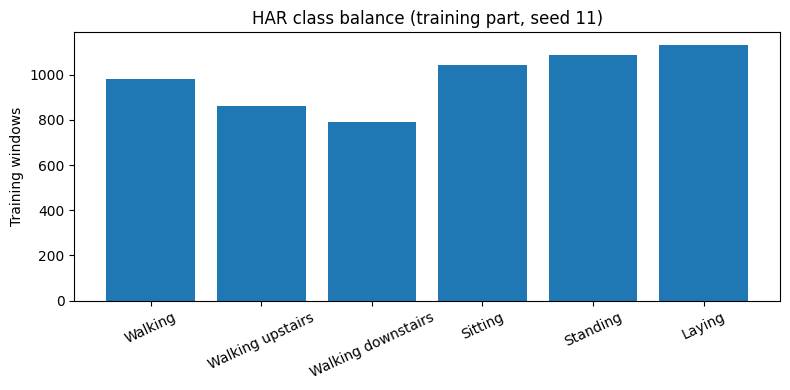

In [3]:
# ---- test: HAR pipeline ----
ld = make_har_loaders(SEEDS[0])
xb, yb = next(iter(ld["train"]))
assert xb.shape[1:] == (128, 9) and yb.dtype == torch.long
assert len(ld["val_subjects"]) == 4
assert set(ld["val_subjects"]).isdisjoint(ld["train_subjects"])
assert set(ld["train_subjects"]).isdisjoint(ld["test_subjects"]) and set(ld["val_subjects"]).isdisjoint(ld["test_subjects"])
Xt = ld["train"].dataset.tensors[0]
assert torch.allclose(Xt.mean((0, 1)), torch.zeros(9), atol=1e-3) and torch.allclose(Xt.std((0, 1), unbiased=False), torch.ones(9), atol=1e-3)
assert np.array_equal(make_har_loaders(SEEDS[0])["val_subjects"], ld["val_subjects"])     # reproducible
print("HAR validation subjects per seed:", {s: make_har_loaders(s)["val_subjects"].tolist() for s in SEEDS})
print("HAR pipeline tests PASSED")

counts = np.bincount(ld["y_train"], minlength=6)
plt.figure(figsize=(8, 4)); plt.bar(ACTIVITY_NAMES, counts)
plt.xticks(rotation=25); plt.ylabel("Training windows"); plt.title(f"HAR class balance (training part, seed {SEEDS[0]})")
savefig("p1_class_balance.png")

**Adding problem:** the generator below is the one provided by the instructor (identical data for every student).
For each T: 10,000 train (seed 0), 1,000 validation (seed 1), 1,000 test (seed 2). Constant-prediction baseline ≈ 0.167.

In [4]:
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

# ---- test: generator ----
for T_ in (50, 101, 400):
    x_, y_ = make_adding(1000, T_, seed=123)
    mk, val = x_[:, :, 1], x_[:, :, 0]
    assert x_.shape == (1000, T_, 2) and y_.shape == (1000,)
    assert np.all(mk.sum(1) == 2)                                   # exactly two markers
    assert np.all(mk[:, :T_ // 2].sum(1) == 1) and np.all(mk[:, T_ // 2:].sum(1) == 1)   # one per half
    assert np.allclose(y_, (val * mk).sum(1), atol=1e-6)            # target = sum of marked values
print("Adding generator tests PASSED")

def make_adding_loaders(T):
    out = {}
    for name, n, seed in zip(("train", "val", "test"), ADD_N, (0, 1, 2)):
        x, y = make_adding(n, T, seed)
        out[name] = DataLoader(TensorDataset(torch.from_numpy(x), torch.from_numpy(y)),
                               batch_size=BATCH_SIZE, shuffle=(name == "train"))
    return out

_, y_test_ = make_adding(ADD_N[2], 100, 2)
BASELINE_MSE = float(np.mean((y_test_ - 1.0) ** 2))
print(f"Constant-prediction (always 1.0) MSE on test = {BASELINE_MSE:.4f}  (theory 1/6 = {1/6:.4f})")

Adding generator tests PASSED
Constant-prediction (always 1.0) MSE on test = 0.1697  (theory 1/6 = 0.1667)


## 2 – RNN, LSTM, GRU cells from scratch (matrix operations only)

Gate order follows PyTorch: LSTM = (i, f, g, o), GRU = (r, z, n). $d$ = input size, $h$ = hidden size.

| cell | equations | hand count (one bias per gate) |
|---|---|---|
| RNN | $h_t=\tanh(W_{ih}x_t+W_{hh}h_{t-1}+b)$ | $hd+h^2+h$ = 576+4096+64 = **4,736** |
| LSTM | 4 gates, each $hd+h^2+h$ | 4·4,736 = **18,944** |
| GRU | 3 gates, each $hd+h^2+h$ | 3·4,736 = **14,208** |

PyTorch keeps **two** bias vectors per gate (`bias_ih`, `bias_hh`; the second is redundant mathematically but is needed for cuDNN compatibility and for the reset-gate form $r\odot(W_{hn}h+b_{hn})$ in the GRU), so it adds $h$ per gate: 4,736+64 = **4,800**, 18,944+256 = **19,200**, 14,208+192 = **14,400**.

In [5]:
def init_gates(w_ih, w_hh, b_ih, b_hh, kind, hidden, forget_bias=1.0):
    """Same initialisation for the from-scratch cells and for the nn.* layers."""
    with torch.no_grad():
        nn.init.xavier_uniform_(w_ih); nn.init.orthogonal_(w_hh)
        b_ih.zero_(); b_hh.zero_()
        if kind == "LSTM":
            b_ih[hidden:2 * hidden].fill_(forget_bias)               # forget-gate slice (gate order i,f,g,o)

class MyRNNCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.weight_ih = nn.Parameter(torch.empty(hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(hidden_size)); self.bias_hh = nn.Parameter(torch.empty(hidden_size))
        init_gates(self.weight_ih, self.weight_hh, self.bias_ih, self.bias_hh, "RNN", hidden_size)
    def forward(self, x, h):                       # x (B,d), h (B,H) -> (B,H)
        return torch.tanh(x @ self.weight_ih.T + self.bias_ih + h @ self.weight_hh.T + self.bias_hh)

class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size, forget_bias=1.0):
        super().__init__()
        self.hidden_size = hidden_size
        self.weight_ih = nn.Parameter(torch.empty(4 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(4 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(4 * hidden_size)); self.bias_hh = nn.Parameter(torch.empty(4 * hidden_size))
        init_gates(self.weight_ih, self.weight_hh, self.bias_ih, self.bias_hh, "LSTM", hidden_size, forget_bias)
    def forward(self, x, state):                   # x (B,d); h,c (B,H)
        h, c = state
        gates = x @ self.weight_ih.T + self.bias_ih + h @ self.weight_hh.T + self.bias_hh   # (B,4H)
        i, f, g, o = gates.chunk(4, dim=1)                                                  # 4 x (B,H)
        i, f, o, g = torch.sigmoid(i), torch.sigmoid(f), torch.sigmoid(o), torch.tanh(g)
        c_new = f * c + i * g                                                               # (B,H)
        h_new = o * torch.tanh(c_new)                                                       # (B,H)
        return h_new, c_new

class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.weight_ih = nn.Parameter(torch.empty(3 * hidden_size, input_size))
        self.weight_hh = nn.Parameter(torch.empty(3 * hidden_size, hidden_size))
        self.bias_ih = nn.Parameter(torch.empty(3 * hidden_size)); self.bias_hh = nn.Parameter(torch.empty(3 * hidden_size))
        init_gates(self.weight_ih, self.weight_hh, self.bias_ih, self.bias_hh, "GRU", hidden_size)
    def forward(self, x, h):                       # x (B,d), h (B,H)
        gi = x @ self.weight_ih.T + self.bias_ih                   # (B,3H)
        gh = h @ self.weight_hh.T + self.bias_hh                   # (B,3H)
        i_r, i_z, i_n = gi.chunk(3, dim=1); h_r, h_z, h_n = gh.chunk(3, dim=1)
        r = torch.sigmoid(i_r + h_r); z = torch.sigmoid(i_z + h_z)
        n = torch.tanh(i_n + r * h_n)
        return (1 - z) * n + z * h

def copy_weights(custom, lib):
    """Copy weights of an nn.RNN / nn.LSTM / nn.GRU (layer 0) into a from-scratch cell."""
    with torch.no_grad():
        for name in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"):
            getattr(custom, name).copy_(getattr(lib, name + "_l0"))

In [6]:
# ---- test: cells match the library layers within 1e-5 on a random batch ----
torch.manual_seed(0)
d, h, B, T_ = 9, 64, 8, 10
x = torch.randn(B, T_, d); h0 = torch.randn(B, h); c0 = torch.randn(B, h)

rnn = nn.RNN(d, h, batch_first=True); cell = MyRNNCell(d, h); copy_weights(cell, rnn)
hh = h0
for t in range(T_): hh = cell(x[:, t], hh)
out_lib, h_lib = rnn(x, h0.unsqueeze(0))
assert (hh - h_lib[0]).abs().max() < 1e-5 and (out_lib[:, -1] - hh).abs().max() < 1e-5
print("RNN  max diff:", (hh - h_lib[0]).abs().max().item())

lstm = nn.LSTM(d, h, batch_first=True); cell = MyLSTMCell(d, h); copy_weights(cell, lstm)
hh, cc = h0, c0
for t in range(T_): hh, cc = cell(x[:, t], (hh, cc))
_, (h_lib, c_lib) = lstm(x, (h0.unsqueeze(0), c0.unsqueeze(0)))
assert (hh - h_lib[0]).abs().max() < 1e-5 and (cc - c_lib[0]).abs().max() < 1e-5
print("LSTM max diff:", (hh - h_lib[0]).abs().max().item(), (cc - c_lib[0]).abs().max().item())

gru = nn.GRU(d, h, batch_first=True); cell = MyGRUCell(d, h); copy_weights(cell, gru)
hh = h0
for t in range(T_): hh = cell(x[:, t], hh)
_, h_lib = gru(x, h0.unsqueeze(0))
assert (hh - h_lib[0]).abs().max() < 1e-5
print("GRU  max diff:", (hh - h_lib[0]).abs().max().item())
print("Cell equivalence tests PASSED")

RNN  max diff: 1.341104507446289e-07
LSTM max diff: 4.470348358154297e-08 5.960464477539063e-08
GRU  max diff: 4.470348358154297e-08
Cell equivalence tests PASSED


In [7]:
# ---- test: parameter counts, hand derivation vs code (d = 9, h = 64) ----
d, h = 9, 64
per_gate = h * d + h * h + h                      # W_ih + W_hh + ONE bias vector per gate
hand = {"RNN": per_gate, "LSTM": 4 * per_gate, "GRU": 3 * per_gate}
gates = {"RNN": 1, "LSTM": 4, "GRU": 3}
mine = {"RNN": MyRNNCell(d, h), "LSTM": MyLSTMCell(d, h), "GRU": MyGRUCell(d, h)}
lib = {"RNN": nn.RNN(d, h), "LSTM": nn.LSTM(d, h), "GRU": nn.GRU(d, h)}
rows = []
for k in MODELS:
    n_mine, n_lib = count_parameters(mine[k]), count_parameters(lib[k])
    rows.append((k, hand[k], n_mine, n_lib, n_mine - hand[k]))
    assert n_mine == n_lib == hand[k] + gates[k] * h          # second bias vector explains the difference
assert [r[1] for r in rows] == [4736, 18944, 14208] and [r[3] for r in rows] == [4800, 19200, 14400]
print(pd.DataFrame(rows, columns=["cell", "hand (1 bias)", "my code", "nn.* layer", "extra = gates*h"]).to_string(index=False))

cell  hand (1 bias)  my code  nn.* layer  extra = gates*h
 RNN           4736     4800        4800               64
LSTM          18944    19200       19200              256
 GRU          14208    14400       14400              192


## Models used for the experiments
LibRecurrent  wraps nn.RNN/LSTM/GRU (fast, cuDNN); CustomRecurrent wraps the from-scratch cells (used for gradient analysis). Both classify / regress from the **last hidden state**.

In [8]:
class LibRecurrent(nn.Module):
    def __init__(self, kind, input_size, hidden_size, out_size, forget_bias=1.0):
        super().__init__()
        self.kind, self.hidden_size = kind, hidden_size
        self.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](input_size, hidden_size, batch_first=True)
        init_gates(self.rnn.weight_ih_l0, self.rnn.weight_hh_l0, self.rnn.bias_ih_l0, self.rnn.bias_hh_l0,
                   kind, hidden_size, forget_bias)
        self.fc = nn.Linear(hidden_size, out_size)
    def forward(self, x):                          # x (B,T,d)
        out, _ = self.rnn(x)                       # (B,T,H)
        return self.fc(out[:, -1])                 # last hidden state -> (B,out)

class CustomRecurrent(nn.Module):
    def __init__(self, kind, input_size, hidden_size, out_size):
        super().__init__()
        self.kind, self.hidden_size = kind, hidden_size
        self.cell = {"RNN": MyRNNCell, "LSTM": MyLSTMCell, "GRU": MyGRUCell}[kind](input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, out_size)
    def forward(self, x, return_states=False):
        h = x.new_zeros(x.size(0), self.hidden_size); c = torch.zeros_like(h); states = []
        for t in range(x.size(1)):
            if self.kind == "LSTM": h, c = self.cell(x[:, t], (h, c))
            else: h = self.cell(x[:, t], h)
            states.append(h)
        out = self.fc(h)
        return (out, states) if return_states else out

def custom_from_library(lib_model, input_size, out_size):
    cm = CustomRecurrent(lib_model.kind, input_size, lib_model.hidden_size, out_size).to(DEVICE)
    copy_weights(cm.cell, lib_model.rnn); cm.fc.load_state_dict(lib_model.fc.state_dict())
    return cm

## Training utilities (identical budget for all models)

In [9]:
def run_epoch(model, loader, task, optimizer=None, grad_clip=GRAD_CLIP):
    training = optimizer is not None
    model.train(training)
    total, n, preds, targs = 0.0, 0, [], []
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for X, y in loader:
        X, y = X.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(training):
            out = model(X)
            if task == "classification":
                loss = nn.functional.cross_entropy(out, y)
            else:
                out = out.squeeze(-1); loss = nn.functional.mse_loss(out, y)
            if training:
                optimizer.zero_grad(set_to_none=True); loss.backward()
                if grad_clip is not None:
                    nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
                optimizer.step()
        total += loss.item() * len(y); n += len(y)
        if task == "classification":
            preds.append(out.argmax(1).cpu().numpy()); targs.append(y.cpu().numpy())
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    res = {"loss": total / n, "sec": time.perf_counter() - t0}
    if task == "classification":
        p, t = np.concatenate(preds), np.concatenate(targs)
        res.update(acc=accuracy_score(t, p), macro_f1=f1_score(t, p, average="macro", zero_division=0), pred=p, true=t)
    return res

def fit(model, loaders, task, epochs, grad_clip=GRAD_CLIP, tag=""):
    """Adam(lr=1e-3). Keeps the epoch with the best validation score and evaluates it on test."""
    opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    hist = {"train": [], "val": [], "sec": []}
    best_state, best_score = None, -np.inf
    for ep in range(epochs):
        tr = run_epoch(model, loaders["train"], task, opt, grad_clip)
        va = run_epoch(model, loaders["val"], task)
        hist["train"].append(tr["loss"]); hist["val"].append(va["loss"]); hist["sec"].append(tr["sec"])
        score = va["macro_f1"] if task == "classification" else -va["loss"]
        if best_state is None or score > best_score:
            best_score, best_state = score, copy.deepcopy(model.state_dict())
        if ep == 0 or (ep + 1) % 5 == 0 or ep == epochs - 1:
            print(f"{tag} ep {ep+1}/{epochs} train {tr['loss']:.4f} val {va['loss']:.4f}"
                  + (f" valF1 {va['macro_f1']:.4f}" if task == "classification" else ""))
    model.load_state_dict(best_state)
    return {"test": run_epoch(model, loaders["test"], task), "hist": hist, "best_val": best_score,
            "sec_per_epoch": float(np.mean(hist["sec"])), "params": count_parameters(model)}

## 3 – HAR classification (RNN vs LSTM vs GRU, 3 seeds)

HAR RNN s11 ep 1/20 train 1.3326 val 1.1561 valF1 0.4978
HAR RNN s11 ep 5/20 train 0.5345 val 0.8397 valF1 0.6794
HAR RNN s11 ep 10/20 train 0.3085 val 0.7868 valF1 0.7749
HAR RNN s11 ep 15/20 train 0.2203 val 0.9829 valF1 0.7588
HAR RNN s11 ep 20/20 train 0.8690 val 0.9655 valF1 0.7921
HAR LSTM s11 ep 1/20 train 1.4342 val 1.2229 valF1 0.4884
HAR LSTM s11 ep 5/20 train 0.3224 val 0.5003 valF1 0.8698
HAR LSTM s11 ep 10/20 train 0.1731 val 0.5771 valF1 0.8675
HAR LSTM s11 ep 15/20 train 0.1041 val 0.6256 valF1 0.8662
HAR LSTM s11 ep 20/20 train 0.0869 val 0.5976 valF1 0.8678
HAR GRU s11 ep 1/20 train 1.4560 val 1.3037 valF1 0.4123
HAR GRU s11 ep 5/20 train 0.2075 val 0.5986 valF1 0.8150
HAR GRU s11 ep 10/20 train 0.1014 val 0.4847 valF1 0.8623
HAR GRU s11 ep 15/20 train 0.0801 val 0.7135 valF1 0.8638
HAR GRU s11 ep 20/20 train 0.0674 val 0.7172 valF1 0.8742
HAR RNN s22 ep 1/20 train 1.3393 val 0.8584 valF1 0.5884
HAR RNN s22 ep 5/20 train 0.6235 val 0.5747 valF1 0.7304
HAR RNN s22 ep 10

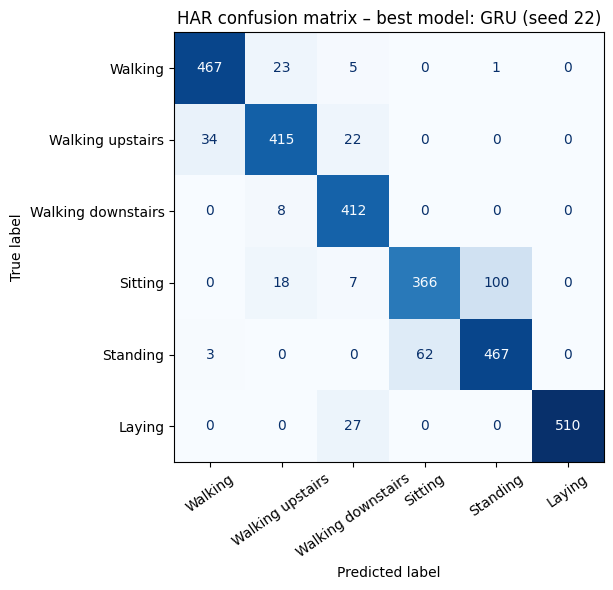

In [10]:
HAR_LOADERS = {s: make_har_loaders(s) for s in SEEDS}
har_rows, best_har = [], None
for seed in SEEDS:
    for kind in MODELS:
        set_seed(seed)
        model = LibRecurrent(kind, 9, HIDDEN_SIZE, 6).to(DEVICE)
        r = fit(model, HAR_LOADERS[seed], "classification", HAR_EPOCHS, tag=f"HAR {kind} s{seed}")
        te = r["test"]
        append_result(problem="P1_HAR", model=kind, seed=seed, seq_len=128, test_acc=te["acc"], macro_f1=te["macro_f1"],
                      params=r["params"], sec_per_epoch=r["sec_per_epoch"],
                      notes=f"hidden={HIDDEN_SIZE}; epochs={HAR_EPOCHS}; adam 1e-3; clip={GRAD_CLIP}")
        har_rows.append(dict(model=kind, seed=seed, acc=te["acc"], f1=te["macro_f1"], params=r["params"], sec=r["sec_per_epoch"]))
        if best_har is None or r["best_val"] > best_har["best_val"]:          # model selection on validation only
            best_har = dict(kind=kind, seed=seed, best_val=r["best_val"], pred=te["pred"], true=te["true"], acc=te["acc"])

har_df = pd.DataFrame(har_rows)
g = har_df.groupby("model")
har_table = pd.DataFrame({
    "test acc (mean ± std)": g["acc"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
    "macro-F1 (mean ± std)": g["f1"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
    "params": g["params"].first(), "sec/epoch": g["sec"].mean().round(3)}).loc[MODELS]
print("\nHAR results, hidden =", HIDDEN_SIZE, f"| epochs = {HAR_EPOCHS} | seeds = {SEEDS}")
print(har_table.to_string())
print(f"\nBest model by validation macro-F1: {best_har['kind']} (seed {best_har['seed']}), test acc {best_har['acc']:.4f}")

cm = confusion_matrix(best_har["true"], best_har["pred"], labels=range(6))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=ACTIVITY_NAMES).plot(ax=ax, xticks_rotation=35, cmap="Blues", colorbar=False)
ax.set_title(f"HAR confusion matrix – best model: {best_har['kind']} (seed {best_har['seed']})")
savefig("p1_har_confusion_matrix.png")

## 4 – Adding problem, T = 50, 100, 200, 400 (3 models × 3 seeds)
A run is **solved** if test MSE < 0.05. Gradient clipping (1.0) is used for all models in this table.

ADD RNN T=50 s11 ep 1/30 train 0.2407 val 0.1713
ADD RNN T=50 s11 ep 5/30 train 0.1657 val 0.1672
ADD RNN T=50 s11 ep 10/30 train 0.1499 val 0.1157
ADD RNN T=50 s11 ep 15/30 train 0.1037 val 0.0889
ADD RNN T=50 s11 ep 20/30 train 0.0800 val 0.0776
ADD RNN T=50 s11 ep 25/30 train 0.0631 val 0.0618
ADD RNN T=50 s11 ep 30/30 train 0.0518 val 0.0528
ADD LSTM T=50 s11 ep 1/30 train 0.2928 val 0.1659
ADD LSTM T=50 s11 ep 5/30 train 0.1653 val 0.1645
ADD LSTM T=50 s11 ep 10/30 train 0.1619 val 0.1577
ADD LSTM T=50 s11 ep 15/30 train 0.0534 val 0.0503
ADD LSTM T=50 s11 ep 20/30 train 0.0280 val 0.0189
ADD LSTM T=50 s11 ep 25/30 train 0.0160 val 0.0126
ADD LSTM T=50 s11 ep 30/30 train 0.0058 val 0.0037
ADD GRU T=50 s11 ep 1/30 train 0.4181 val 0.1620
ADD GRU T=50 s11 ep 5/30 train 0.1561 val 0.1517
ADD GRU T=50 s11 ep 10/30 train 0.0117 val 0.0092
ADD GRU T=50 s11 ep 15/30 train 0.0063 val 0.0045
ADD GRU T=50 s11 ep 20/30 train 0.0056 val 0.0053
ADD GRU T=50 s11 ep 25/30 train 0.0023 val 0.0018

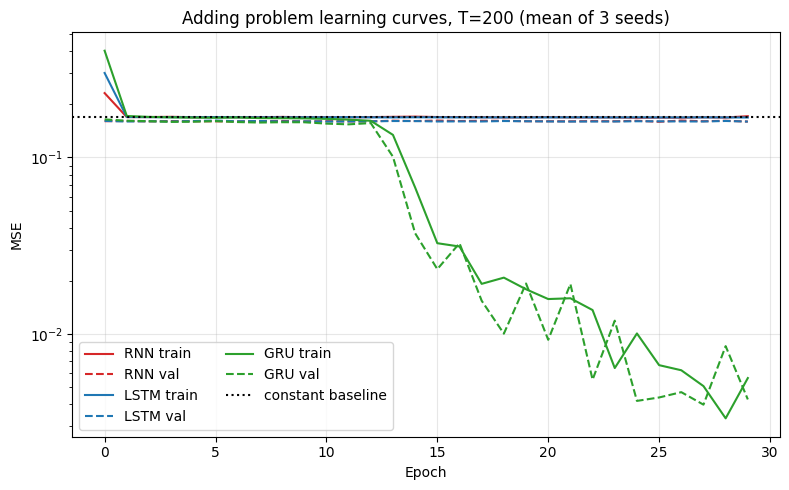

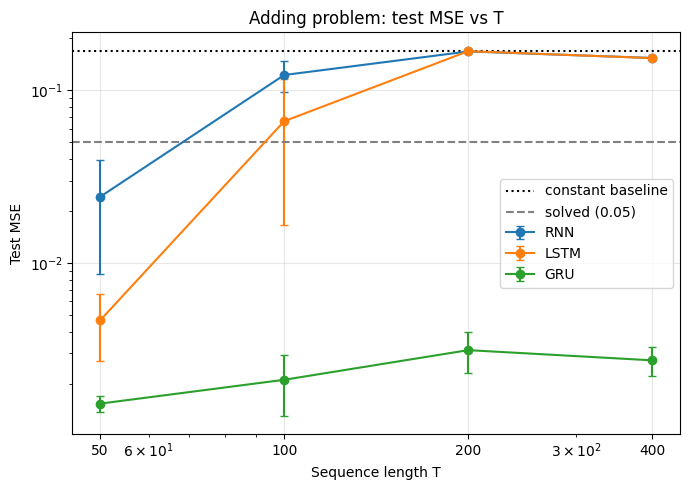

In [11]:
add_rows, ADD_CURVES, TRAINED_T100 = [], {}, {}
for T in ADD_LENGTHS:
    loaders = make_adding_loaders(T)
    for seed in SEEDS:
        for kind in MODELS:
            set_seed(seed)
            model = LibRecurrent(kind, 2, HIDDEN_SIZE, 1, forget_bias=1.0).to(DEVICE)
            r = fit(model, loaders, "regression", ADD_EPOCHS, tag=f"ADD {kind} T={T} s{seed}")
            mse = r["test"]["loss"]
            append_result(problem="P1_Adding", model=kind, seed=seed, seq_len=T, test_mse=mse, params=r["params"],
                          sec_per_epoch=r["sec_per_epoch"],
                          notes=f"hidden={HIDDEN_SIZE}; epochs={ADD_EPOCHS}; clip={GRAD_CLIP}; solved={mse < SOLVED_MSE}")
            add_rows.append(dict(model=kind, T=T, seed=seed, mse=mse, solved=bool(mse < SOLVED_MSE)))
            ADD_CURVES[(kind, T, seed)] = r["hist"]
            if T == 100 and seed == SEEDS[0]:
                TRAINED_T100[kind] = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

add_df = pd.DataFrame(add_rows)
g = add_df.groupby(["model", "T"])
add_table = pd.DataFrame({"test MSE (mean ± std)": g["mse"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                          "solved": g["solved"].sum().astype(int).astype(str) + f"/{len(SEEDS)}"}).unstack("model")
print(f"Adding problem (baseline MSE ≈ {BASELINE_MSE:.3f}; solved = test MSE < {SOLVED_MSE})")
print(add_table.to_string())

# learning curves at T = 200 (mean over seeds)
plt.figure(figsize=(8, 5))
for kind, col in zip(MODELS, ["tab:red", "tab:blue", "tab:green"]):
    tr = np.mean([ADD_CURVES[(kind, 200, s)]["train"] for s in SEEDS], axis=0)
    va = np.mean([ADD_CURVES[(kind, 200, s)]["val"] for s in SEEDS], axis=0)
    plt.plot(tr, color=col, label=f"{kind} train"); plt.plot(va, "--", color=col, label=f"{kind} val")
plt.axhline(BASELINE_MSE, color="k", ls=":", label="constant baseline")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("MSE"); plt.title(f"Adding problem learning curves, T=200 (mean of {len(SEEDS)} seeds)")
plt.legend(ncol=2); plt.grid(alpha=.3); savefig("p1_adding_curves_T200.png")

# test MSE against T
plt.figure(figsize=(7, 5))
for kind in MODELS:
    s = add_df[add_df.model == kind].groupby("T")["mse"]
    plt.errorbar(ADD_LENGTHS, s.mean().values, yerr=s.std(ddof=1).fillna(0).values, marker="o", capsize=3, label=kind)
plt.axhline(BASELINE_MSE, color="k", ls=":", label="constant baseline"); plt.axhline(SOLVED_MSE, color="gray", ls="--", label="solved (0.05)")
plt.xscale("log"); plt.yscale("log"); plt.xticks(ADD_LENGTHS, ADD_LENGTHS); plt.xlabel("Sequence length T"); plt.ylabel("Test MSE")
plt.title("Adding problem: test MSE vs T"); plt.legend(); plt.grid(alpha=.3); savefig("p1_adding_mse_vs_T.png")

##  5(a) – Gradient norm ‖∂L/∂h_t‖ against t (T = 100, log scale)
Uses the from-scratch cells (needs $\partial L/\partial h_t$ at every step). *After training* = the T=100 model of the first seed from the table above, its weights copied into the from-scratch model; *before* = the same seed's initial weights.

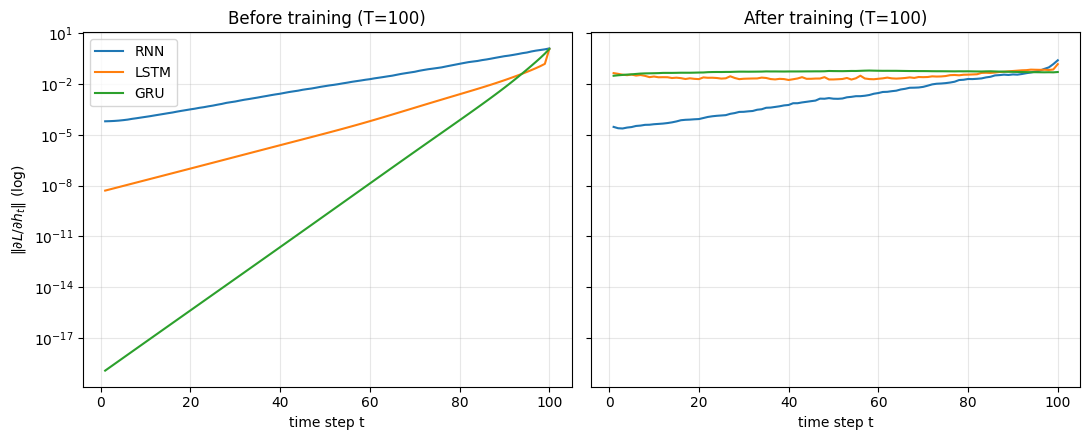

RNN: grad at t=1 / grad at t=100 -> before 4.92e-05, after 1.15e-04
LSTM: grad at t=1 / grad at t=100 -> before 4.23e-09, after 2.94e-01
GRU: grad at t=1 / grad at t=100 -> before 9.54e-20, after 6.01e-01


In [12]:
Xg_np, yg_np = make_adding(256, 100, 2)
Xg, yg = torch.from_numpy(Xg_np).to(DEVICE), torch.from_numpy(yg_np).to(DEVICE)

def gradient_profile(cmodel):
    cmodel.zero_grad()
    out, states = cmodel(Xg, return_states=True)
    for s in states: s.retain_grad()
    nn.functional.mse_loss(out.squeeze(-1), yg, reduction="sum").backward()      # sum -> per-sample gradients not divided by B
    return np.array([s.grad.norm(dim=1).mean().item() for s in states])         # mean over samples of ||dL/dh_t||

profiles = {}
for kind in MODELS:
    set_seed(SEEDS[0]); init_model = LibRecurrent(kind, 2, HIDDEN_SIZE, 1, forget_bias=1.0).to(DEVICE)   # identical to the run's start
    trained = LibRecurrent(kind, 2, HIDDEN_SIZE, 1).to(DEVICE); trained.load_state_dict(TRAINED_T100[kind])
    profiles[kind] = (gradient_profile(custom_from_library(init_model, 2, 1)), gradient_profile(custom_from_library(trained, 2, 1)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, idx, title in zip(axes, (0, 1), ("Before training", "After training")):
    for kind in MODELS:
        ax.plot(np.arange(1, 101), np.maximum(profiles[kind][idx], 1e-30), label=kind)
    ax.set_yscale("log"); ax.set_xlabel("time step t"); ax.set_title(f"{title} (T=100)"); ax.grid(alpha=.3, which="both")
axes[0].set_ylabel(r"$\|\partial L/\partial h_t\|$ (log)"); axes[0].legend()
savefig("p1_gradient_norm_T100.png")
for kind in MODELS:
    b, a = profiles[kind]
    print(f"{kind}: grad at t=1 / grad at t=100 -> before {b[0]/b[-1]:.2e}, after {a[0]/a[-1]:.2e}")

##  5(b) – Hidden-size sweep on HAR (LSTM, GRU)

SWEEP LSTM h=16 s11 ep 1/20 train 1.6542 val 1.5612 valF1 0.3703
SWEEP LSTM h=16 s11 ep 5/20 train 0.7215 val 0.9217 valF1 0.6642
SWEEP LSTM h=16 s11 ep 10/20 train 0.3489 val 0.6759 valF1 0.7994
SWEEP LSTM h=16 s11 ep 15/20 train 0.2298 val 0.6016 valF1 0.8209
SWEEP LSTM h=16 s11 ep 20/20 train 0.1845 val 0.6571 valF1 0.8218
SWEEP LSTM h=16 s22 ep 1/20 train 1.6952 val 1.5243 valF1 0.3983
SWEEP LSTM h=16 s22 ep 5/20 train 0.7715 val 0.7290 valF1 0.6213
SWEEP LSTM h=16 s22 ep 10/20 train 0.5486 val 0.4595 valF1 0.8754
SWEEP LSTM h=16 s22 ep 15/20 train 0.3102 val 0.2650 valF1 0.9310
SWEEP LSTM h=16 s22 ep 20/20 train 0.1802 val 0.1783 valF1 0.9283
SWEEP LSTM h=16 s33 ep 1/20 train 1.7388 val 1.6070 valF1 0.4075
SWEEP LSTM h=16 s33 ep 5/20 train 0.7303 val 0.7484 valF1 0.7547
SWEEP LSTM h=16 s33 ep 10/20 train 0.2927 val 0.5174 valF1 0.8569
SWEEP LSTM h=16 s33 ep 15/20 train 0.1841 val 0.4857 valF1 0.8792
SWEEP LSTM h=16 s33 ep 20/20 train 0.1777 val 0.5027 valF1 0.8779
SWEEP LSTM h=32 

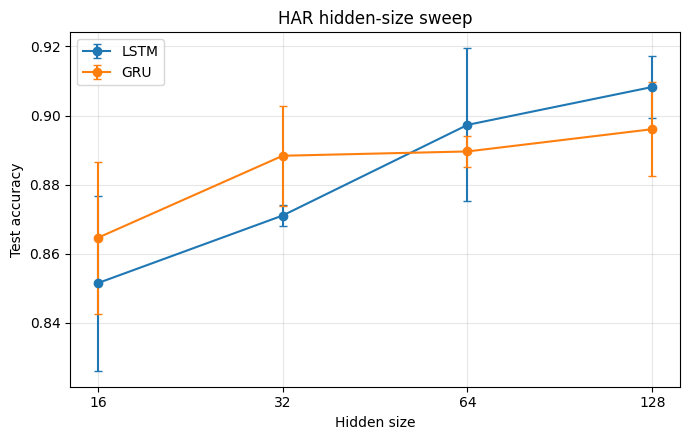

In [13]:
sweep_rows = []
for kind in ["LSTM", "GRU"]:
    for hs in HIDDEN_SIZES:
        for seed in SEEDS:
            set_seed(seed)
            model = LibRecurrent(kind, 9, hs, 6).to(DEVICE)
            r = fit(model, HAR_LOADERS[seed], "classification", SWEEP_EPOCHS, tag=f"SWEEP {kind} h={hs} s{seed}")
            te = r["test"]
            append_result(problem="P1_HAR_sweep", model=kind, seed=seed, seq_len=128, test_acc=te["acc"], macro_f1=te["macro_f1"],
                          params=r["params"], sec_per_epoch=r["sec_per_epoch"], notes=f"hidden={hs}; epochs={SWEEP_EPOCHS}")
            sweep_rows.append(dict(model=kind, hidden=hs, seed=seed, acc=te["acc"], f1=te["macro_f1"], params=r["params"], sec=r["sec_per_epoch"]))
sweep_df = pd.DataFrame(sweep_rows)
g = sweep_df.groupby(["model", "hidden"])
sweep_table = pd.DataFrame({"acc (mean ± std)": g["acc"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                            "macro-F1": g["f1"].mean().round(4), "params": g["params"].first(), "sec/epoch": g["sec"].mean().round(3)})
print(sweep_table.to_string())
plt.figure(figsize=(7, 4.5))
for kind in ["LSTM", "GRU"]:
    s = sweep_df[sweep_df.model == kind].groupby("hidden")["acc"]
    plt.errorbar(HIDDEN_SIZES, s.mean().values, yerr=s.std(ddof=1).fillna(0).values, marker="o", capsize=3, label=kind)
plt.xscale("log", base=2); plt.xticks(HIDDEN_SIZES, HIDDEN_SIZES); plt.xlabel("Hidden size"); plt.ylabel("Test accuracy")
plt.title("HAR hidden-size sweep"); plt.legend(); plt.grid(alpha=.3); savefig("p1_hidden_size_sweep.png")

## 5(c) – Individual ablation (chosen by the last digit of the student ID)
Even: vanilla-RNN gradient clipping (norm 1.0 vs none) at T = 200. Odd: LSTM forget-gate bias 0 vs 1 at T = 200.

Ablation: LSTM, T=200: forget-gate bias initialisation
ABL LSTM forget bias=0 s11 ep 1/30 train 0.3871 val 0.1628
ABL LSTM forget bias=0 s11 ep 5/30 train 0.1701 val 0.1645
ABL LSTM forget bias=0 s11 ep 10/30 train 0.1690 val 0.1601
ABL LSTM forget bias=0 s11 ep 15/30 train 0.1695 val 0.1599
ABL LSTM forget bias=0 s11 ep 20/30 train 0.1686 val 0.1630
ABL LSTM forget bias=0 s11 ep 25/30 train 0.1692 val 0.1597
ABL LSTM forget bias=0 s11 ep 30/30 train 0.1686 val 0.1597
ABL LSTM forget bias=0 s22 ep 1/30 train 0.3751 val 0.1625
ABL LSTM forget bias=0 s22 ep 5/30 train 0.1698 val 0.1608
ABL LSTM forget bias=0 s22 ep 10/30 train 0.1688 val 0.1609
ABL LSTM forget bias=0 s22 ep 15/30 train 0.1691 val 0.1598
ABL LSTM forget bias=0 s22 ep 20/30 train 0.1686 val 0.1601
ABL LSTM forget bias=0 s22 ep 25/30 train 0.1689 val 0.1598
ABL LSTM forget bias=0 s22 ep 30/30 train 0.1686 val 0.1597
ABL LSTM forget bias=0 s33 ep 1/30 train 0.4443 val 0.1624
ABL LSTM forget bias=0 s33 ep 5/30 train 0.1699 va

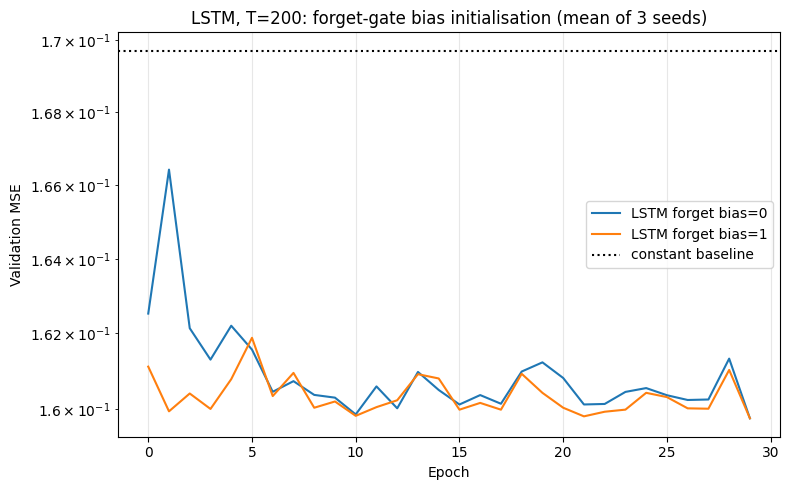

In [14]:
T_ABL = 200
if STUDENT_ID_LAST_DIGIT % 2 == 0:
    title = "Vanilla RNN, T=200: gradient clipping"
    configs = [("RNN clip=1.0", "RNN", 1.0, GRAD_CLIP), ("RNN no clipping", "RNN", 1.0, None)]
else:
    title = "LSTM, T=200: forget-gate bias initialisation"
    configs = [("LSTM forget bias=0", "LSTM", 0.0, GRAD_CLIP), ("LSTM forget bias=1", "LSTM", 1.0, GRAD_CLIP)]
print("Ablation:", title)

abl_loaders = make_adding_loaders(T_ABL)
abl_rows, abl_curves = [], {}
for label, kind, fb, clip in configs:
    for seed in SEEDS:
        set_seed(seed)
        model = LibRecurrent(kind, 2, HIDDEN_SIZE, 1, forget_bias=fb).to(DEVICE)
        r = fit(model, abl_loaders, "regression", ABL_EPOCHS, grad_clip=clip, tag=f"ABL {label} s{seed}")
        mse = r["test"]["loss"]
        append_result(problem="P1_ablation", model=label, seed=seed, seq_len=T_ABL, test_mse=mse, params=r["params"],
                      sec_per_epoch=r["sec_per_epoch"], notes=f"{title}; epochs={ABL_EPOCHS}; solved={mse < SOLVED_MSE}")
        abl_rows.append(dict(config=label, seed=seed, mse=mse, solved=bool(mse < SOLVED_MSE)))
        abl_curves[(label, seed)] = r["hist"]
abl_df = pd.DataFrame(abl_rows); g = abl_df.groupby("config", sort=False)
print(pd.DataFrame({"test MSE (mean ± std)": g["mse"].agg(lambda s: f"{s.mean():.4f} ± {s.std(ddof=1):.4f}"),
                    "solved": g["solved"].sum().astype(int).astype(str) + f"/{len(SEEDS)}"}).to_string())
plt.figure(figsize=(8, 5))
for label, *_ in configs:
    plt.plot(np.mean([abl_curves[(label, s)]["val"] for s in SEEDS], axis=0), label=label)
plt.axhline(BASELINE_MSE, color="k", ls=":", label="constant baseline")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Validation MSE"); plt.title(title + f" (mean of {len(SEEDS)} seeds)")
plt.legend(); plt.grid(alpha=.3); savefig("p1_ablation_5c.png")

##  5(d) – One-page analysis (write in report.pdf)
Use only numbers from the tables/figures above: (1) what the gradient plot says about memory (ratio of gradient at t=1 vs t=100, before/after training); (2) where each model fails as T grows (solved-run table, MSE vs T); (3) accuracy–parameters–time trade-off (HAR table, hidden-size sweep); (4) wearable recommendation with reasons from the tables.

In [15]:
res = pd.read_csv(RESULTS_CSV)
print("results.csv rows:", len(res), "| columns:", list(res.columns) == CSV_COLUMNS)
print(res.groupby("problem").size())
print("Figures:", sorted(os.listdir(FIG_DIR)))

results.csv rows: 75 | columns: True
problem
P1_Adding       36
P1_HAR           9
P1_HAR_sweep    24
P1_ablation      6
dtype: int64
Figures: ['p1_ablation_5c.png', 'p1_adding_curves_T200.png', 'p1_adding_mse_vs_T.png', 'p1_class_balance.png', 'p1_gradient_norm_T100.png', 'p1_har_confusion_matrix.png', 'p1_hidden_size_sweep.png']
